# Individual predictor selection with the L1 penalty (post-hoc)

Nested L1 logistic regression with all 83 predictors in the LOYO design, new-event skill, and half-sample stability selection (100 complementary half-samples).

**Thesis:** Sections 3.10, 4.10 · Table 4.14 · Fig. 4.13 · Appendix C.11  
**Input:** predictor_table_1982_2025.csv  
**Output:** oof_l1/*, l1_*.csv

Runs on Google Colab with the folder layout described in the repository README (`/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/...`). The printed outputs below are from the original run used in the thesis.

# Nested L1 (lasso) logistic regression + stability selection
Post-hoc, exploratory analysis for the MHW thesis. Uses the same leave-one-year-out design
as the thesis (purge, 30-day embargo, inner year-grouped CV, isotonic calibration,
MCC-optimal threshold, year-block bootstrap). Self-contained: it loads the processed files
from Google Drive and needs no earlier notebook cell.

**Decision rules, fixed before running**
1. L1 adds skill only if its paired MCC gain over the SST-only logistic model has a 95% CI > 0 at 5 AND 7 days.
2. A predictor is robust if it is selected (coefficient != 0) in >= 80% of the 44 folds and keeps
   the same sign in >= 95% of the folds where it is selected.
3. ERA5 / climate indices carry a usable signal only if at least one of their predictors is robust at both 5 and 7 days.

Run the cells from top to bottom. Every lead is saved to Drive when it finishes, so if Colab
disconnects, run all cells again and finished leads are read back instead of recomputed.

In [1]:
# Settings
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

PROC = '/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/processed'   # same folder as the thesis
OUT  = f'{PROC}/oof_l1'                       # all new outputs go here; thesis files are never overwritten
FIG  = f'{PROC}/figures'
os.makedirs(OUT, exist_ok=True); os.makedirs(FIG, exist_ok=True)

LEADS = [7, 5, 1, 3, 10, 14]                  # 7 and 5 days first: rules 1 and 3 need them
L1_C  = (0.0005, 0.001, 0.003, 0.01, 0.03)    # smaller C = stronger penalty = fewer predictors
SEL_MIN, SIGN_MIN = 0.80, 0.95                # rule 2
EPS = 1e-8                                    # |coef| above this counts as "selected"
B_BOOT = 2000                                 # bootstrap resamples, as in the thesis
print('scikit-learn', sklearn.__version__)

Mounted at /content/drive
scikit-learn 1.6.1


In [2]:
# Load the processed data
need = [f'{PROC}/features_det_t+7.csv', f'{PROC}/predictor_table_1982_2025.csv',
        f'{PROC}/feature_groups.json']
missing = [f for f in need if not os.path.exists(f)]
assert not missing, f'Missing files (check PROC): {missing}'

groups = json.load(open(f'{PROC}/feature_groups.json'))
FSETS = {'sst': groups['sst'] + groups['calendar'],
         'all': groups['sst'] + groups['calendar'] + groups['era5'] + groups['indices']}
GRP = {c: g for g, cs in groups.items() for c in cs}

feat = pd.read_csv(f'{PROC}/features_det_t+7.csv', index_col=0, parse_dates=True)
feat = feat.drop(columns=[c for c in ('y', 'target_year') if c in feat.columns])
if 'year' not in feat.columns:
    feat['year'] = feat.index.year
lab_det = pd.read_csv(f'{PROC}/predictor_table_1982_2025.csv', index_col=0,
                      parse_dates=True).mhw_detrended

def table_for(h):
    """Predictors on day t (built only from days <= t); target = detrended MHW label on day t+h."""
    y = lab_det.shift(-h).reindex(feat.index)
    tb = feat.assign(y=y, target_year=(feat.index + pd.Timedelta(days=h)).year).dropna(subset=['y'])
    tb['y'] = tb.y.astype(int)
    return tb

YEARS = sorted(feat.year.unique())
COLS = FSETS['all']
assert all(c in feat.columns for c in COLS), 'a predictor from feature_groups.json is missing'
print(f'{len(feat)} days, {len(YEARS)} years ({YEARS[0]}-{YEARS[-1]}), {len(COLS)} predictors:',
      {g: len(c) for g, c in groups.items()})

16035 days, 44 years (1982-2025), 83 predictors: {'sst': 17, 'era5': 56, 'indices': 8, 'calendar': 2}


In [3]:
# Evaluation functions (same as thesis Appendix C.6)
def train_mask(tab, test_years):
    """Drop the test years, rows whose target is in a test year (purge) and the first
    30 days after a test year (embargo)."""
    m = ~tab.year.isin(test_years) & ~tab.target_year.isin(test_years)
    after = tab.year.isin([y + 1 for y in test_years]) & (tab.index.dayofyear <= 30)
    return m & ~after

def mcc_from(tp, fp, fn, tn):
    tp, fp, fn, tn = (np.asarray(v, dtype=float) for v in (tp, fp, fn, tn))
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return np.where(den > 0, (tp * tn - fp * fn) / np.where(den > 0, den, 1), 0.0)

def best_threshold(y, p):
    """Threshold with the highest MCC (0.01 grid plus the calibrated values)."""
    u = np.unique(p)
    extra = u if len(u) <= 500 else np.quantile(p, np.linspace(0.5, 1, 301))
    th = np.unique(np.r_[np.arange(0.01, 1.0, 0.01), extra])
    th = th[(th > 0) & (th < 1)]
    P = p[None, :] >= th[:, None]
    tp = (P & (y == 1)).sum(1); fp = (P & (y == 0)).sum(1)
    fn = ((~P) & (y == 1)).sum(1); tn = ((~P) & (y == 0)).sum(1)
    m = mcc_from(tp, fp, fn, tn)
    return th[np.argmax(m)], m.max()

def onset_rows(o):
    prev = o.y.shift(1); consecutive = (o.index.to_series().diff().dt.days == 1).values
    return (o.y == 1) & (prev == 0) & consecutive

def metrics(o, clim):
    y, p = o.y.values, o.prob.values
    r = {'PR_AUC': average_precision_score(y, p) if y.any() else np.nan,
         'BSS': 1 - np.mean((p - y) ** 2) / np.mean((clim.prob.reindex(o.index).values - y) ** 2)}
    pr = o.pred.values.astype(int)
    tp = int(((pr == 1) & (y == 1)).sum()); fp = int(((pr == 1) & (y == 0)).sum())
    fn = int(((pr == 0) & (y == 1)).sum()); tn = int(((pr == 0) & (y == 0)).sum())
    on = onset_rows(o)
    r.update(MCC=float(mcc_from(tp, fp, fn, tn)), onset_hit=float(o.pred[on].mean()),
             TP=tp, FP=fp, FN=fn, TN=tn)
    return r

def year_counts(o):
    g = o.assign(tp=(o.pred == 1) & (o.y == 1), fp=(o.pred == 1) & (o.y == 0),
                 fn=(o.pred == 0) & (o.y == 1), tn=(o.pred == 0) & (o.y == 0)).groupby('year')
    return g[['tp', 'fp', 'fn', 'tn']].sum().reindex(YEARS).fillna(0).values

def bootstrap(o, refs, B=B_BOOT, seed=0):
    """Resample whole years; MCC from summed counts; paired gain vs each reference on the same resamples."""
    idx = np.random.default_rng(seed).integers(0, len(YEARS), (B, len(YEARS)))
    m = mcc_from(*year_counts(o)[idx].sum(1).T)
    out = {'MCC_lo': np.percentile(m, 2.5), 'MCC_hi': np.percentile(m, 97.5)}
    for rn, ro in refs.items():
        d = m - mcc_from(*year_counts(ro)[idx].sum(1).T)
        out[f'gain_vs_{rn}_lo'] = np.percentile(d, 2.5)
        out[f'gain_vs_{rn}_hi'] = np.percentile(d, 97.5)
    return out

In [4]:
# Models and the LOYO loop
_new = tuple(int(v) for v in sklearn.__version__.split('.')[:2]) >= (1, 8)
_L1 = {'l1_ratio': 1.0} if _new else {'penalty': 'l1'}       # scikit-learn 1.8 renamed the L1 switch

l1 = lambda C: (lambda: make_pipeline(StandardScaler(),
                    LogisticRegression(solver='liblinear', C=C, class_weight='balanced',
                                       max_iter=5000, **_L1)))
l2 = lambda C: (lambda: make_pipeline(StandardScaler(),
                    LogisticRegression(C=C, class_weight='balanced', max_iter=3000)))
L1_GRID = [(f'C={C}', l1(C)) for C in L1_C]
L2_GRID = [(f'C={C}', l2(C)) for C in (0.01, 0.1, 1.0)]       # the thesis logit grid

def loyo(tab, cols, grid, inner_folds=4, tag=''):
    """Thesis LOYO. Inside each training fold only: inner year-grouped CV picks C (max MCC),
    isotonic calibration on the inner out-of-fold probabilities, MCC-optimal threshold.
    Also returns the coefficients of the final model of every fold."""
    rows, coefs, t0 = [], {}, time.time()
    years = sorted(tab.year.unique())
    for k, y in enumerate(years, 1):
        tr, te = tab[train_mask(tab, [y])], tab[tab.year == y]
        chunks = np.array_split(np.array(sorted(tr.year.unique())), inner_folds)
        best = None
        for lab, make in grid:
            oof = pd.Series(np.nan, index=tr.index)
            for ch in chunks:
                itr, iva = tr[train_mask(tr, list(ch))], tr[tr.year.isin(ch)]
                oof.loc[iva.index] = make().fit(itr[cols], itr.y).predict_proba(iva[cols])[:, 1]
            ok = oof.notna()
            score = best_threshold(tr.y[ok].values, oof[ok].values)[1]
            if best is None or score > best[0]:
                best = (score, lab, make, oof[ok], tr.y[ok])
        _, lab, make, oof, yo = best
        iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(oof.values, yo.values)
        th, _ = best_threshold(yo.values, iso.predict(oof.values))
        fit = make().fit(tr[cols], tr.y)
        coefs[y] = pd.Series(fit[-1].coef_[0], index=cols)
        p = iso.predict(fit.predict_proba(te[cols])[:, 1])
        rows.append(pd.DataFrame({'year': y, 'y': te.y.values, 'prob': p,
                                  'pred': (p >= th).astype(int), 'thr': th, 'params': lab},
                                 index=te.index))
        if k % 11 == 0 or k == len(years):
            print(f'  {tag} fold {k}/{len(years)} ({(time.time() - t0) / 60:.1f} min)')
    return pd.concat(rows), pd.DataFrame(coefs).T

In [5]:
# Reference forecasts: read the thesis files, or rebuild them if they are missing
rd = lambda p: pd.read_csv(p, index_col=0, parse_dates=True)
thesis_dir = lambda h: f'{PROC}/oof_p5' if h == 7 else f'{PROC}/oof_lead{h}'

def honest_persistence(tab):
    p = tab.mhw_causal.astype(float)
    return pd.DataFrame({'year': tab.year, 'y': tab.y, 'prob': p, 'pred': p.astype(int)}, index=tab.index)

def climatology(tab):
    rows = []
    for y in YEARS:
        tr, te = tab[train_mask(tab, [y])], tab[tab.year == y]
        if len(te) == 0: continue
        pm = tr.y.groupby(tr.index.month).mean()
        rows.append(pd.DataFrame({'year': y, 'y': te.y.values,
                                  'prob': pm.reindex(te.index.month).values}, index=te.index))
    return pd.concat(rows)

def references(h, tab):
    refs = {}
    for name in ('persistence', 'climatology', 'logit_sst'):
        f_thesis, f_new = f'{thesis_dir(h)}/{name}_det.csv', f'{OUT}/ref_{name}_lead{h}.csv'
        if os.path.exists(f_thesis):
            refs[name] = rd(f_thesis); src = 'thesis file'
        elif os.path.exists(f_new):
            refs[name] = rd(f_new); src = 'rebuilt earlier'
        else:
            if name == 'persistence':  refs[name] = honest_persistence(tab)
            elif name == 'climatology': refs[name] = climatology(tab)
            else: refs[name], _ = loyo(tab, FSETS['sst'], L2_GRID, tag=f'logit_sst lead {h}')
            refs[name].to_csv(f_new); src = 'rebuilt now'
        print(f'  reference {name:12s} lead {h:2d} d: {src}')
    return refs

In [6]:
# Run the L1 model at every lead
def stability(cf):
    nz = cf.abs() > EPS
    same = np.maximum((cf > EPS).sum(), (cf < -EPS).sum()) / nz.sum().replace(0, np.nan)
    return pd.DataFrame({'group': pd.Series(GRP), 'sel_freq': nz.mean(), 'same_sign': same,
                         'median_coef': cf.where(nz).median()}
                        ).loc[cf.columns].sort_values('sel_freq', ascending=False)

def family(c):
    """Physical variable of an ERA5 / index / calendar predictor (SST predictors are excluded)."""
    g = GRP[c]
    if g == 'era5':    return c.split('_')[0]
    if g == 'indices': return 'rmm' if c.startswith('rmm') else c.split('_')[0]
    return 'doy'

def family_stability(cf):
    nz = cf.abs() > EPS
    fam = pd.Series({c: family(c) for c in cf.columns if GRP[c] != 'sst'})
    return pd.Series({f: nz[list(cs)].any(axis=1).mean() for f, cs in fam.groupby(fam).groups.items()},
                     name='any_member_selected').sort_values(ascending=False)

summary, stab, fstab = [], {}, {}
for h in LEADS:
    print(f'=== lead {h} d')
    tab = table_for(h)
    f_o, f_c = f'{OUT}/l1_all_lead{h}.csv', f'{OUT}/l1_coef_lead{h}.csv'
    if os.path.exists(f_o) and os.path.exists(f_c):
        o, cf = rd(f_o), pd.read_csv(f_c, index_col=0)
        print('  L1 model: read back from Drive')
    else:
        o, cf = loyo(tab, COLS, L1_GRID, tag=f'L1 lead {h}')
        o.to_csv(f_o); cf.to_csv(f_c)
    refs = references(h, tab)
    r = metrics(o, refs['climatology'])
    r.update(bootstrap(o, {'persistence': refs['persistence'], 'logit_sst': refs['logit_sst']}))
    r['MCC_logit_sst'] = metrics(refs['logit_sst'], refs['climatology'])['MCC']
    r['n_selected_median'] = int((cf.abs() > EPS).sum(axis=1).median())
    r['C_chosen'] = o.groupby('year').params.first().value_counts().to_dict()
    summary.append(pd.Series(r, name=h))
    stab[h], fstab[h] = stability(cf), family_stability(cf)

S = pd.DataFrame(summary).sort_index()
S.to_csv(f'{OUT}/l1_skill_summary.csv')
SF = pd.DataFrame({h: stab[h].sel_freq for h in sorted(stab)}).reindex(COLS)
SF.insert(0, 'group', pd.Series(GRP))
SF.to_csv(f'{OUT}/l1_selection_frequency_by_lead.csv')
print('Saved to', OUT)

=== lead 7 d
  L1 model: read back from Drive
  reference persistence  lead  7 d: thesis file
  reference climatology  lead  7 d: thesis file
  reference logit_sst    lead  7 d: thesis file
=== lead 5 d
  L1 model: read back from Drive
  reference persistence  lead  5 d: thesis file
  reference climatology  lead  5 d: thesis file
  reference logit_sst    lead  5 d: thesis file
=== lead 1 d
  L1 model: read back from Drive
  reference persistence  lead  1 d: thesis file
  reference climatology  lead  1 d: thesis file
  reference logit_sst    lead  1 d: thesis file
=== lead 3 d
  L1 model: read back from Drive
  reference persistence  lead  3 d: thesis file
  reference climatology  lead  3 d: thesis file
  reference logit_sst    lead  3 d: thesis file
=== lead 10 d
  L1 model: read back from Drive
  reference persistence  lead 10 d: thesis file
  reference climatology  lead 10 d: thesis file
  reference logit_sst    lead 10 d: thesis file
=== lead 14 d
  L1 model: read back from Drive
  

In [7]:
# Results and the three decision rules
pd.set_option('display.width', 250)
show = ['MCC', 'MCC_lo', 'MCC_hi', 'MCC_logit_sst', 'gain_vs_logit_sst_lo', 'gain_vs_logit_sst_hi',
        'gain_vs_persistence_lo', 'gain_vs_persistence_hi', 'BSS', 'n_selected_median']
print('Skill of the L1 model (83 predictors) vs the SST-only logistic model and honest persistence')
print(S[show].astype(float).round(3).to_string())
print(f'\nPenalty chosen in the {len(YEARS)} folds (a choice at the edge of L1_C means the grid should be widened):')
for h, c in S.C_chosen.items(): print(f'  lead {h:2d} d: {c}')

robust = {h: st[(st.sel_freq >= SEL_MIN) & (st.same_sign >= SIGN_MIN)] for h, st in stab.items()}
for h in sorted(stab):
    print(f'\n=== lead {h} d | robust predictors (selected >= {SEL_MIN:.0%}, same sign >= {SIGN_MIN:.0%})')
    print(robust[h].round(2).to_string())
    nonsst = stab[h][stab[h].group.isin(['era5', 'indices']) & (stab[h].sel_freq >= 0.5)]
    print(f'--- ERA5 / index predictors selected in >= 50% of folds')
    print(nonsst.round(2).to_string() if len(nonsst) else '(none)')
    print('--- share of folds in which ANY predictor of a variable was selected')
    print(fstab[h].round(2).to_string())

print('\n================ DECISION RULES ================')
both = [h for h in (5, 7) if h in S.index]
if len(both) == 2:
    r1 = all(S.loc[h, 'gain_vs_logit_sst_lo'] > 0 for h in both)
    print(f'Rule 1  L1 adds skill over SST-only logistic at 5 and 7 d: {"YES" if r1 else "NO"}')
    rob57 = set(robust[5].index) & set(robust[7].index)
    print(f'Rule 2  predictors robust at both 5 and 7 d: {sorted(rob57) if rob57 else "none"}')
    nonsst57 = sorted(c for c in rob57 if GRP[c] in ('era5', 'indices'))
    print(f'Rule 3  ERA5 / index predictor robust at 5 and 7 d: {nonsst57 if nonsst57 else "NO"}')
else:
    print('Rules need leads 5 and 7: keep both in LEADS.')

Skill of the L1 model (83 predictors) vs the SST-only logistic model and honest persistence
      MCC  MCC_lo  MCC_hi  MCC_logit_sst  gain_vs_logit_sst_lo  gain_vs_logit_sst_hi  gain_vs_persistence_lo  gain_vs_persistence_hi    BSS  n_selected_median
1   0.783   0.748   0.813          0.783                -0.011                 0.011                   0.131                   0.192  0.686               30.0
3   0.616   0.562   0.660          0.616                -0.019                 0.020                   0.141                   0.227  0.460               23.0
5   0.479   0.407   0.537          0.458                 0.003                 0.038                   0.116                   0.202  0.300               12.0
7   0.381   0.285   0.450          0.361                -0.024                 0.056                   0.065                   0.169  0.203               14.0
10  0.297   0.213   0.365          0.287                -0.045                 0.057                   0.039     

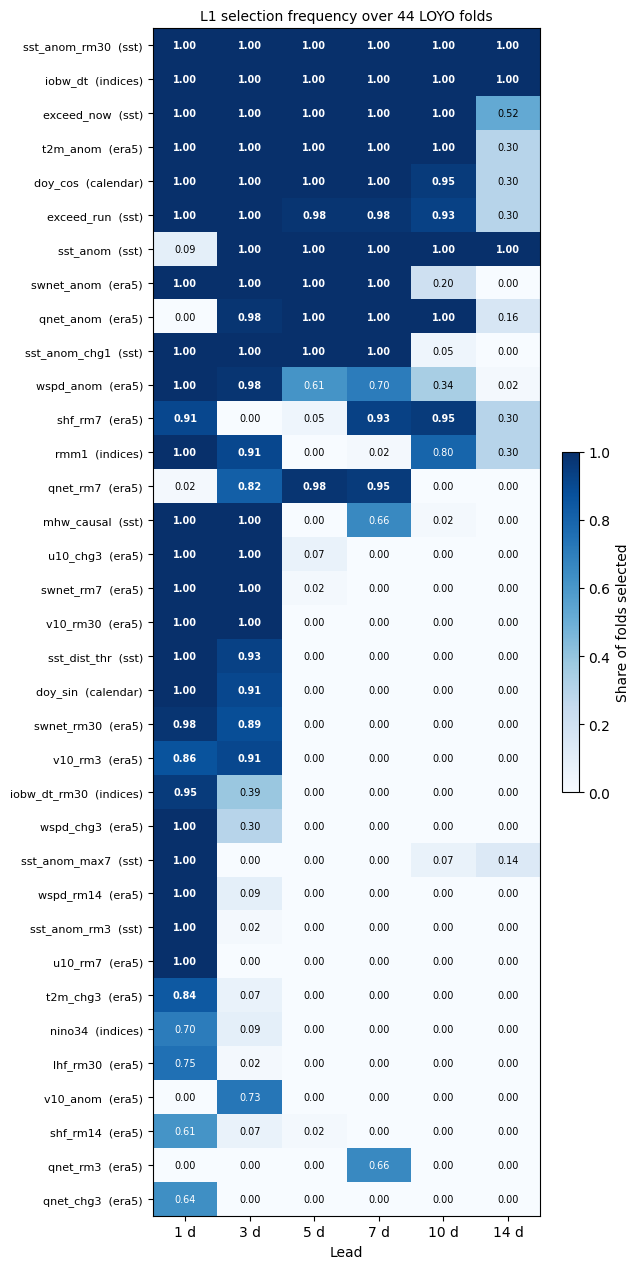

In [8]:
# Figure: selection frequency by lead
plot = SF.drop(columns='group')
plot = plot[(plot >= 0.5).any(axis=1)]                        # predictors selected in >= 50% of folds at some lead
plot = plot.loc[plot.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6.5, 0.32 * len(plot) + 1.6))
im = ax.imshow(plot.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(plot.shape[1]), [f'{h} d' for h in plot.columns])
ax.set_yticks(range(len(plot)), [f'{c}  ({GRP[c]})' for c in plot.index], fontsize=8)
for i in range(plot.shape[0]):
    for j in range(plot.shape[1]):
        v = plot.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7,
                color='white' if v > 0.6 else 'black', fontweight='bold' if v >= SEL_MIN else 'normal')
ax.set_xlabel('Lead'); ax.set_title(f'L1 selection frequency over {len(YEARS)} LOYO folds', fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.04, label='Share of folds selected')
fig.tight_layout(); fig.savefig(f'{FIG}/l1_selection_frequency.png', dpi=200); plt.show()

## Part 2: half-sample stability selection, wider C grid where needed, new-event MCC
Why: the 44 LOYO training sets share 43 of 44 years, so selection frequency over LOYO folds mostly
repeats the full-data fit. Here the model is refitted on 100 half-samples of the years
(50 complementary pairs, Shah and Samworth 2013), so each fit sees genuinely different data.

**Decision rules for Part 2, fixed before running**
- A. A predictor is stable if it is selected in >= 80% of the 100 half-samples and keeps the same sign in >= 95% of them.
- B. ERA5 / climate indices have a stable signal only if at least one of their predictors is stable at both 5 and 7 days.
- C. L1 adds new-event skill only if its paired new-event MCC gain over the SST-only model has a 95% CI > 0 at both 5 and 7 days.

Run Part 1 first (Cells 1-7); Part 1 results are read back from Drive, so "Run all" is cheap.

In [9]:
# Part 2 settings and the wider C grid where the LOYO choice sat at the edge
N_PAIRS = 50                         # 50 complementary pairs = 100 half-samples of the years
PI_THR, SIGN_THR = 0.80, 0.95        # rule A
SEED = 2026
EXT_HI, EXT_LO = (0.1, 0.3), (0.0002, 0.0001)

def chosen_C(o):
    return o.groupby('year').params.first().str.split('=').str[1].astype(float)

def edge_share(o, grid_C):
    c = chosen_C(o)
    return (c == max(grid_C)).mean(), (c == min(grid_C)).mean()

L1_FINAL = {}                        # lead -> (LOYO forecasts, LOYO coefficients, C grid used)
for h in LEADS:
    o = rd(f'{OUT}/l1_all_lead{h}.csv'); cf = pd.read_csv(f'{OUT}/l1_coef_lead{h}.csv', index_col=0)
    grid_C = tuple(L1_C)
    hi, lo = edge_share(o, grid_C)
    if hi >= 0.5:   grid_C = tuple(sorted(L1_C + EXT_HI))
    elif lo >= 0.5: grid_C = tuple(sorted(EXT_LO + L1_C))
    if grid_C != tuple(L1_C):
        f_o, f_c = f'{OUT}/l1w_all_lead{h}.csv', f'{OUT}/l1w_coef_lead{h}.csv'
        if os.path.exists(f_o) and os.path.exists(f_c):
            o, cf = rd(f_o), pd.read_csv(f_c, index_col=0)
            print(f'lead {h:2d} d: wider-grid run read back from Drive')
        else:
            print(f'lead {h:2d} d: {max(hi, lo):.0%} of folds at the grid edge -> rerun with C in {grid_C}')
            o, cf = loyo(table_for(h), COLS, [(f'C={C}', l1(C)) for C in grid_C], tag=f'L1 wide lead {h}')
            o.to_csv(f_o); cf.to_csv(f_c)
        hi2, lo2 = edge_share(o, grid_C)
        if max(hi2, lo2) >= 0.5:
            print(f'  WARNING lead {h} d: still at the edge of {grid_C}; widen EXT_HI / EXT_LO and rerun')
    L1_FINAL[h] = (o, cf, grid_C)
    print(f'lead {h:2d} d: C chosen {chosen_C(o).value_counts().to_dict()}')

lead  7 d: C chosen {0.003: 44}
lead  5 d: C chosen {0.003: 44}
lead  1 d: 100% of folds at the grid edge -> rerun with C in (0.0005, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3)
  L1 wide lead 1 fold 11/44 (4.7 min)
  L1 wide lead 1 fold 22/44 (9.8 min)
  L1 wide lead 1 fold 33/44 (14.8 min)
  L1 wide lead 1 fold 44/44 (19.3 min)
lead  1 d: C chosen {0.03: 24, 0.1: 20}
lead  3 d: C chosen {0.01: 43, 0.03: 1}
lead 10 d: C chosen {0.003: 42, 0.001: 2}
lead 14 d: C chosen {0.001: 30, 0.003: 13, 0.0005: 1}


In [10]:
# Skill over all days and on new-event days (honest MHW state of day t = 0)
mcc_of = lambda o: float(mcc_from(*year_counts(o).sum(0)))

rows = []
for h in LEADS:
    o, cf, gC = L1_FINAL[h]
    tab = table_for(h)
    refs = references(h, tab)
    ls = refs['logit_sst']
    new_o  = tab.mhw_causal.reindex(o.index) == 0
    new_ls = tab.mhw_causal.reindex(ls.index) == 0
    b_all = bootstrap(o, {'logit_sst': ls})
    b_new = bootstrap(o[new_o], {'logit_sst': ls[new_ls]})
    rows.append(pd.Series({
        'MCC_L1': mcc_of(o), 'MCC_sst': mcc_of(ls),
        'gain_lo': b_all['gain_vs_logit_sst_lo'], 'gain_hi': b_all['gain_vs_logit_sst_hi'],
        'newMCC_L1': mcc_of(o[new_o]), 'newMCC_sst': mcc_of(ls[new_ls]),
        'new_gain_lo': b_new['gain_vs_logit_sst_lo'], 'new_gain_hi': b_new['gain_vs_logit_sst_hi'],
        'C_grid': 'wide' if gC != tuple(L1_C) else 'original'}, name=h))
SK = pd.DataFrame(rows).sort_index()
SK.to_csv(f'{OUT}/l1_skill_with_new_event.csv')
print('\nL1 (83 predictors) vs SST-only logistic: all days and new-event days (paired 95% CIs)')
print(SK.round(3).to_string())

  reference persistence  lead  7 d: thesis file
  reference climatology  lead  7 d: thesis file
  reference logit_sst    lead  7 d: thesis file
  reference persistence  lead  5 d: thesis file
  reference climatology  lead  5 d: thesis file
  reference logit_sst    lead  5 d: thesis file
  reference persistence  lead  1 d: thesis file
  reference climatology  lead  1 d: thesis file
  reference logit_sst    lead  1 d: thesis file
  reference persistence  lead  3 d: thesis file
  reference climatology  lead  3 d: thesis file
  reference logit_sst    lead  3 d: thesis file
  reference persistence  lead 10 d: thesis file
  reference climatology  lead 10 d: thesis file
  reference logit_sst    lead 10 d: thesis file
  reference persistence  lead 14 d: thesis file
  reference climatology  lead 14 d: thesis file
  reference logit_sst    lead 14 d: thesis file

L1 (83 predictors) vs SST-only logistic: all days and new-event days (paired 95% CIs)
    MCC_L1  MCC_sst  gain_lo  gain_hi  newMCC_L1 

In [11]:
# Half-sample stability selection (complementary pairs)
def half_sample_coefs(h, C_full, n_pairs=N_PAIRS, seed=SEED):
    """Refit the L1 model on 2 * n_pairs half-samples of the years (complementary pairs).
    liblinear sums the loss over rows, so with half the rows the same penalty balance needs 2 * C."""
    f = f'{OUT}/l1_halfsample_coef_lead{h}.csv'
    if os.path.exists(f):
        return pd.read_csv(f, index_col=0)
    tab = table_for(h)
    yrs = np.array(sorted(tab.year.unique()))
    rng = np.random.default_rng(seed + h)
    out, t0 = [], time.time()
    for k in range(n_pairs):
        perm = rng.permutation(yrs)
        for half in (perm[: len(yrs) // 2], perm[len(yrs) // 2:]):
            sub = tab[tab.year.isin(half)]
            out.append(l1(2 * C_full)().fit(sub[COLS], sub.y)[-1].coef_[0])
        if (k + 1) % 25 == 0:
            print(f'  lead {h} d: {2 * (k + 1)}/{2 * n_pairs} half-samples ({(time.time() - t0) / 60:.1f} min)')
    cf = pd.DataFrame(out, columns=COLS)
    cf.to_csv(f); return cf

HS, HSF, MB = {}, {}, {}
for h in LEADS:
    o, cf_loyo, gC = L1_FINAL[h]
    C_full = chosen_C(o).value_counts().idxmax()           # the C the LOYO folds chose most often
    cf = half_sample_coefs(h, C_full)
    HS[h], HSF[h] = stability(cf), family_stability(cf)
    q = (cf.abs() > EPS).sum(axis=1).mean()                # mean number of predictors selected per fit
    MB[h] = (q, q ** 2 / ((2 * PI_THR - 1) * len(COLS)))    # Meinshausen-Buehlmann bound on false selections
    print(f'lead {h:2d} d: C = {C_full} (half-samples use {2 * C_full}), '
          f'{q:.1f} predictors per fit, expected false selections at pi = {PI_THR:.0%}: <= {MB[h][1]:.1f}')

HSFREQ = pd.DataFrame({h: HS[h].sel_freq for h in sorted(HS)}).reindex(COLS)
HSFREQ.insert(0, 'group', pd.Series(GRP))
HSFREQ.to_csv(f'{OUT}/l1_halfsample_selection_frequency_by_lead.csv')

stable = {h: HS[h][(HS[h].sel_freq >= PI_THR) & (HS[h].same_sign >= SIGN_THR)] for h in HS}
for h in sorted(HS):
    print(f'\n=== lead {h} d | stable predictors (half-samples: selected >= {PI_THR:.0%}, same sign >= {SIGN_THR:.0%})')
    print(stable[h].round(2).to_string())
    print('--- share of half-samples in which ANY predictor of a variable was selected')
    print(HSF[h].round(2).to_string())

# LOYO vs half-sample frequency for the non-SST predictors that looked robust in Part 1
cand = sorted({c for h in (5, 7) if h in stab for c in
               stab[h][(stab[h].sel_freq >= SEL_MIN) & stab[h].group.isin(['era5', 'indices'])].index})
if cand:
    cmp_ = pd.concat({f'LOYO {h} d': stab[h].sel_freq.reindex(cand) for h in (5, 7) if h in stab} |
                     {f'half {h} d': HS[h].sel_freq.reindex(cand) for h in (5, 7) if h in HS}, axis=1)
    print('\nNon-SST predictors robust in Part 1: LOYO-fold vs half-sample selection frequency')
    print(cmp_.round(2).to_string())

  lead 7 d: 50/100 half-samples (0.1 min)
  lead 7 d: 100/100 half-samples (0.2 min)
lead  7 d: C = 0.003 (half-samples use 0.006), 17.0 predictors per fit, expected false selections at pi = 80%: <= 5.8
  lead 5 d: 50/100 half-samples (0.1 min)
  lead 5 d: 100/100 half-samples (0.2 min)
lead  5 d: C = 0.003 (half-samples use 0.006), 15.4 predictors per fit, expected false selections at pi = 80%: <= 4.8
  lead 1 d: 50/100 half-samples (0.6 min)
  lead 1 d: 100/100 half-samples (1.2 min)
lead  1 d: C = 0.03 (half-samples use 0.06), 33.5 predictors per fit, expected false selections at pi = 80%: <= 22.5
  lead 3 d: 50/100 half-samples (0.3 min)
  lead 3 d: 100/100 half-samples (0.5 min)
lead  3 d: C = 0.01 (half-samples use 0.02), 26.3 predictors per fit, expected false selections at pi = 80%: <= 13.9
  lead 10 d: 50/100 half-samples (0.1 min)
  lead 10 d: 100/100 half-samples (0.2 min)
lead 10 d: C = 0.003 (half-samples use 0.006), 16.1 predictors per fit, expected false selections at pi

================ PART 2 DECISION RULES ================
Rule A  predictors stable at both 5 and 7 d: ['iobw_dt', 'qnet_anom', 'sst_anom', 'sst_anom_chg1', 'sst_anom_rm30', 'swnet_anom']
Rule B  ERA5 / index predictor stable at 5 and 7 d: ['iobw_dt', 'qnet_anom', 'swnet_anom']
Rule C  L1 adds new-event skill at 5 and 7 d: NO
(Expected false selections among the stable set, upper bound: 4.8 at 5 d, 5.8 at 7 d)


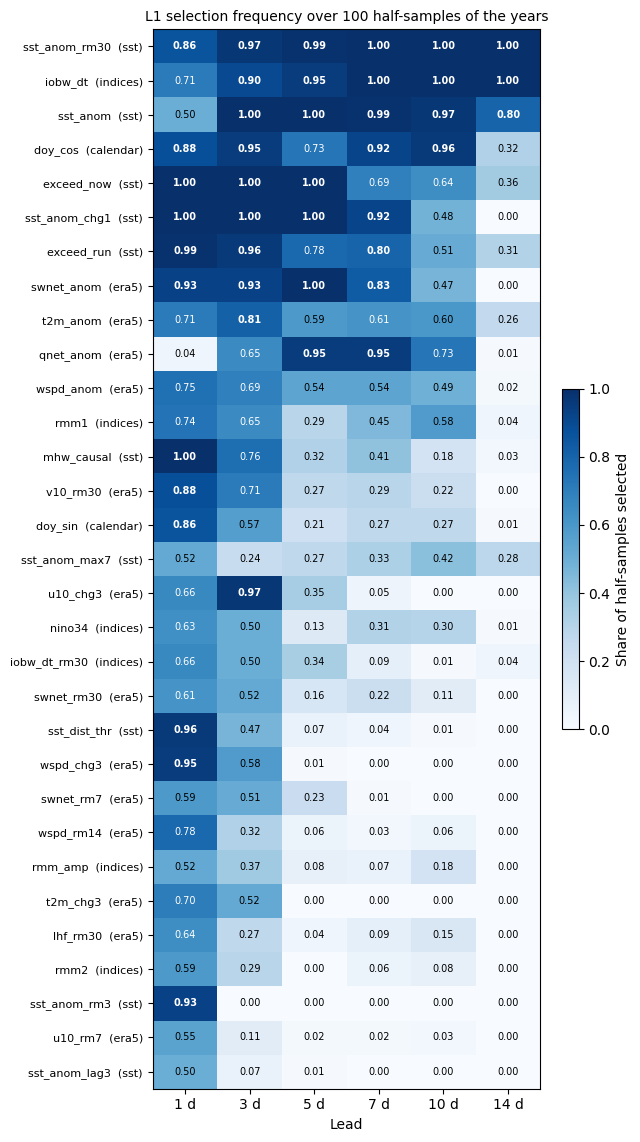

In [12]:
# Part 2 decision rules and figure
print('================ PART 2 DECISION RULES ================')
if all(h in HS for h in (5, 7)):
    st57 = set(stable[5].index) & set(stable[7].index)
    print(f'Rule A  predictors stable at both 5 and 7 d: {sorted(st57) if st57 else "none"}')
    nonsst = sorted(c for c in st57 if GRP[c] in ('era5', 'indices'))
    print(f'Rule B  ERA5 / index predictor stable at 5 and 7 d: {nonsst if nonsst else "NO"}')
    rC = all(SK.loc[h, 'new_gain_lo'] > 0 for h in (5, 7))
    print(f'Rule C  L1 adds new-event skill at 5 and 7 d: {"YES" if rC else "NO"}')
    print(f'(Expected false selections among the stable set, upper bound: '
          f'{MB[5][1]:.1f} at 5 d, {MB[7][1]:.1f} at 7 d)')
else:
    print('Rules need leads 5 and 7: keep both in LEADS.')

plot = HSFREQ.drop(columns='group')
plot = plot[(plot >= 0.5).any(axis=1)]
plot = plot.loc[plot.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6.5, 0.32 * len(plot) + 1.6))
im = ax.imshow(plot.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(plot.shape[1]), [f'{h} d' for h in plot.columns])
ax.set_yticks(range(len(plot)), [f'{c}  ({GRP[c]})' for c in plot.index], fontsize=8)
for i in range(plot.shape[0]):
    for j in range(plot.shape[1]):
        v = plot.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7,
                color='white' if v > 0.6 else 'black', fontweight='bold' if v >= PI_THR else 'normal')
ax.set_xlabel('Lead')
ax.set_title(f'L1 selection frequency over {2 * N_PAIRS} half-samples of the years', fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.04, label='Share of half-samples selected')
fig.tight_layout(); fig.savefig(f'{FIG}/l1_halfsample_selection_frequency.png', dpi=200); plt.show()